# **Project Information**
**Project Title**: Student Performance Risk Prediction System

**Training  Program**: 45-Day Industrial Training

**Submitted By**:
- Rajwinder Kaur
- Jeenam
- Pari
- Varun Kumar

**Organization**: Solitaire Infosys Pvt. Ltd.

**Project Mentor**: Mr.Arshdeep singh

**Year**: July-August 2026

This notebook presents the complete implementation of the **Studnet Performance Risk Prediction System** developed as part of a group project during the 45-Day Industrial Training. It covers the entire machine learning workflow, including data exploration, exploratory data analysis(EDA), data preprocessing, model training, model evaluation, hyperparameter tuning,model saving, and deployment preparation.



# Student Performance Risk Prediction System

## Problem Statement

Student academic performance is influenced by multiple factors such as attendance, GPA, assignment completion, socioeconomic status, online learning engagement, laboratory performance, and extracurricular participation. Identifying students who are at academic risk at an early stage enables educational institutions to provide timely support and improve learning outcomes.

The objective of this project is to develop a Machine Learning model that predicts whether a student is at academic risk using demographic, academic, and behavioral features. The prediction is represented as a binary classification problem where:

- **0** → Not At Risk
- **1** → At Risk

The developed model can assist educators in identifying students who may require additional academic guidance, counseling, or intervention.

## Importing Required Libraries

In this section, we import the Python libraries required for data manipulation, visualization, preprocessing, machine learning model development, and evaluation.

In [2]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

## Loading the Dataset
The student performance dataset is loaded into a Pandas Dataframe. This dataset contains demographic, academic, and engagement-related features that will be used to predict whether a student is at academic risk.

In [3]:
# Load the dataset
df = pd.read_csv("C:/Users/rr617/OneDrive/Desktop/Student_Project/risk_students (3).csv")

## Dataset Exploration
Before performing any analysis , it is important to understand the structure and the quality of the dataset. This includes examining the number of observations, feature names, data types, missing values, duplicate record, andd basic statistical information.

In [9]:
# Get first 5 rows
df.head()

,Age,Gender,Socio_Economic_Status,GPA,Attendance_Rate,Assignments_Submitted,Online_Learning_Hours,Forum_Participation,Lab_Performance,Extracurricular_Participation,At_Risk
0,24,Female,Low,3.23,98.1,8,8.1,2,59,0.0,0
1,21,Female,High,3.82,81.4,6,0.4,6,73,0.0,0
2,28,Female,NaN,3.02,59.2,4,1.2,1,48,1.0,1
3,25,Male,Low,3.00,55.3,4,6.3,1,14,1.0,1
4,22,Female,High,2.10,90.6,16,14.1,2,82,0.0,0


## Observation
The first five records of the dataset were displayed to verify that the data was loaded successfully and to gain an initial understanding of the features and their values.

In [12]:
# To Get last 5 rows
df.tail()

,Age,Gender,Socio_Economic_Status,GPA,Attendance_Rate,Assignments_Submitted,Online_Learning_Hours,Forum_Participation,Lab_Performance,Extracurricular_Participation,At_Risk
1995,24,Male,NaN,2.70,90.6,4,8.5,3,21,1.0,0
1996,22,Male,Low,2.25,87.6,8,1.7,2,82,1.0,0
1997,24,Female,High,2.26,87.7,3,2.1,2,44,0.0,0
1998,20,Male,Low,3.35,85.8,3,4.5,1,73,0.0,0
1999,29,Female,High,3.72,83.5,15,NaN,2,60,1.0,0


## Observation
The last five records of the dataset were examine to ensure the dataset was loaded completely and to inspect the ending entries

In [13]:
# Get any random no.of rows
df.sample(5)

,Age,Gender,Socio_Economic_Status,GPA,Attendance_Rate,Assignments_Submitted,Online_Learning_Hours,Forum_Participation,Lab_Performance,Extracurricular_Participation,At_Risk
300,20,Male,High,2.10,88.5,14,11.1,3,70,0.0,0
108,28,Male,High,3.19,62.6,7,13.1,5,63,0.0,0
1114,24,Male,High,2.47,81.8,4,8.1,6,31,1.0,1
1945,27,Female,High,3.31,95.2,2,11.5,2,89,1.0,0
609,26,Female,Medium,2.12,54.9,14,13.4,0,52,0.0,0


## Observation
A random sample of the dataset was displayed to observe randomly selelcted records and verify data consistency.

In [14]:
# To check no. of rows and columns
df.shape

(2000, 11)

## Observation
The dataset contains 2000 **rows** and 11 **columns**, indicating the total number of observations andd features available for analysis.

In [15]:
# Get column names
df.columns

Index(['Age', 'Gender', 'Socio_Economic_Status', 'GPA', 'Attendance_Rate',
       'Assignments_Submitted', 'Online_Learning_Hours', 'Forum_Participation',
       'Lab_Performance', 'Extracurricular_Participation', 'At_Risk'],
      dtype='object')

## Observation
The dataset consist of feature columns, representing demogrpahic, academic, and engagement-related information, along with the variable target variable **At Risk**.

In [16]:
# To check detailed information with memory usage
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            2000 non-null   int64  
 1   Gender                         2000 non-null   object 
 2   Socio_Economic_Status          1981 non-null   object 
 3   GPA                            2000 non-null   float64
 4   Attendance_Rate                1991 non-null   float64
 5   Assignments_Submitted          2000 non-null   int64  
 6   Online_Learning_Hours          1996 non-null   float64
 7   Forum_Participation            2000 non-null   int64  
 8   Lab_Performance                2000 non-null   int64  
 9   Extracurricular_Participation  1997 non-null   float64
 10  At_Risk                        2000 non-null   int64  
dtypes: float64(4), int64(5), object(2)
memory usage: 172.0+ KB


## Observation
The dataset contains both numerical and categorical features. The output provides information about non-null values and helps identify columns with missing data.

In [17]:
# To check statistical information
df.describe()

,Age,GPA,Attendance_Rate,Assignments_Submitted,Online_Learning_Hours,Forum_Participation,Lab_Performance,Extracurricular_Participation,At_Risk
count,2000.000000,2000.000000,1991.000000,2000.000000,1996.000000,2000.000000,2000.000000,1997.000000,2000.000000
mean,23.465500,2.985180,74.656404,9.612500,7.565030,4.400000,49.031500,0.501753,0.288500
std,3.500419,0.574557,14.390081,5.696716,4.286298,2.870212,28.769139,0.500122,0.453178
min,18.000000,2.000000,50.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,20.000000,2.497500,62.100000,5.000000,3.900000,2.000000,24.000000,0.000000,0.000000
50%,23.000000,2.970000,74.400000,10.000000,7.600000,4.000000,49.000000,1.000000,0.000000
75%,27.000000,3.472500,87.100000,15.000000,11.300000,7.000000,74.000000,1.000000,1.000000
max,29.000000,4.000000,100.000000,19.000000,15.000000,9.000000,99.000000,1.000000,1.000000


## Observation
The statistical summary provides measures such as count, mean, standard deviation, minimum, maximum, and quartiles for numerical features, helping to understand the distribution of the data.

In [18]:
# To check data type of each column
df.dtypes

Age                                int64
Gender                            object
Socio_Economic_Status             object
GPA                              float64
Attendance_Rate                  float64
Assignments_Submitted              int64
Online_Learning_Hours            float64
Forum_Participation                int64
Lab_Performance                    int64
Extracurricular_Participation    float64
At_Risk                            int64
dtype: object

## Observation
The dataset contains a combination of numerical and categorical data types which will require appropriate preprocessing before model training.

In [19]:
# To Check missing Values
df.isnull().sum()

Age                               0
Gender                            0
Socio_Economic_Status            19
GPA                               0
Attendance_Rate                   9
Assignments_Submitted             0
Online_Learning_Hours             4
Forum_Participation               0
Lab_Performance                   0
Extracurricular_Participation     3
At_Risk                           0
dtype: int64

## Observation
Missing values are present in **4** columns (Socio_Economic_Status, Attendance_Rate,Online_Learning_Hours, Extracurricular_Participation). These will be handled during the preprocessing stage using appropriate imputation techniques.

In [20]:
# To check duplicates
df.duplicated().sum()

np.int64(0)

## Observation
No duplicate records were found in the dataset, indicating good data quality.

# Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the distribution of variables, identify patterns, detect outliers, and examine relationships between features and the target variable. These insights help in selecting appropriate preprocessing techniques and machine learning models.

## Univariate Analysis

Univariate analysis examines each variable individually to understand its distribution, frequency, central tendency, variability, and potential outliers.

# Numerical Features

# 1. Age

In [21]:
# value count of age
df["Age"].value_counts()

Age
18    191
29    179
20    176
27    172
25    171
22    169
24    162
23    161
26    161
19    157
28    152
21    149
Name: count, dtype: int64

In [22]:
# To check statistical information
df["Age"].describe()

count    2000.000000
mean       23.465500
std         3.500419
min        18.000000
25%        20.000000
50%        23.000000
75%        27.000000
max        29.000000
Name: Age, dtype: float64

(array([191.,   0., 157.,   0., 176.,   0., 149.,   0.,   0., 169.,   0.,
        161.,   0., 162.,   0., 171.,   0.,   0., 161.,   0., 172.,   0.,
        152.,   0., 179.]),
 array([18.  , 18.44, 18.88, 19.32, 19.76, 20.2 , 20.64, 21.08, 21.52,
        21.96, 22.4 , 22.84, 23.28, 23.72, 24.16, 24.6 , 25.04, 25.48,
        25.92, 26.36, 26.8 , 27.24, 27.68, 28.12, 28.56, 29.  ]),
 <BarContainer object of 25 artists>)

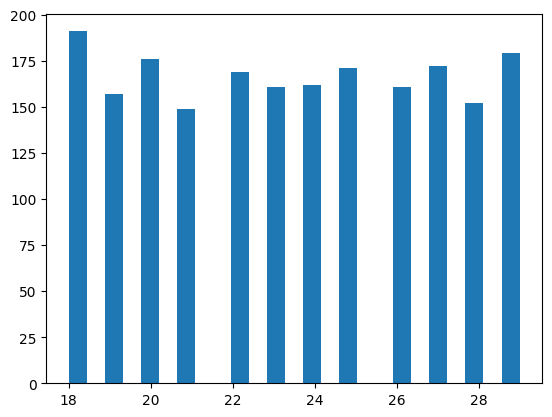

In [134]:
# plotting Histogram plot
plt.hist(df["Age"], bins = 25)

<Axes: ylabel='Age'>

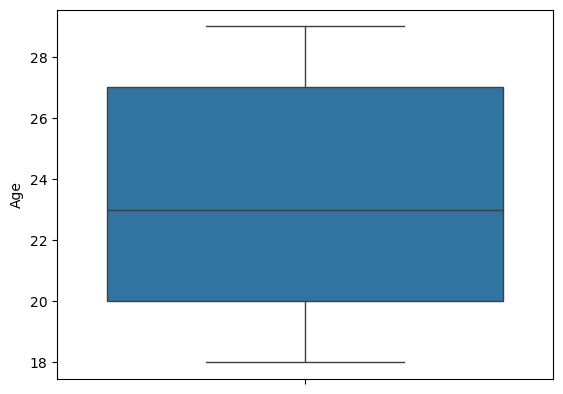

In [23]:
# Boxplot
sns.boxplot(df["Age"])

C:\Users\rr617\AppData\Local\Temp\ipykernel_9652\3760910948.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Age"])


<Axes: xlabel='Age', ylabel='Density'>

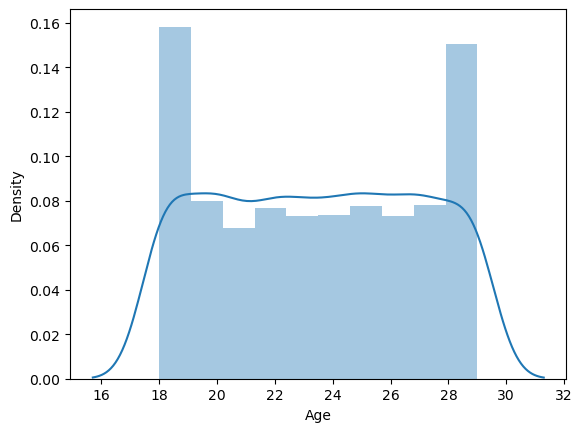

In [24]:
# Distribution plot
sns.distplot(df["Age"])

## Observation

- The age of students ranges from 18 to 29 years.
- Most students are concentrated in the early 20s, with an average age of approximately 23.5 years.
- The distribution appears to be fairly balanced without extreme skewness.
- There is no significant outliers in the Age feature
- Age alone may not strongly indicate whether a student is at risk, but it can be useful when combined with other features during model training.



# 2. GPA

In [25]:
# To check statistical information
df["GPA"].describe()

count    2000.000000
mean        2.985180
std         0.574557
min         2.000000
25%         2.497500
50%         2.970000
75%         3.472500
max         4.000000
Name: GPA, dtype: float64

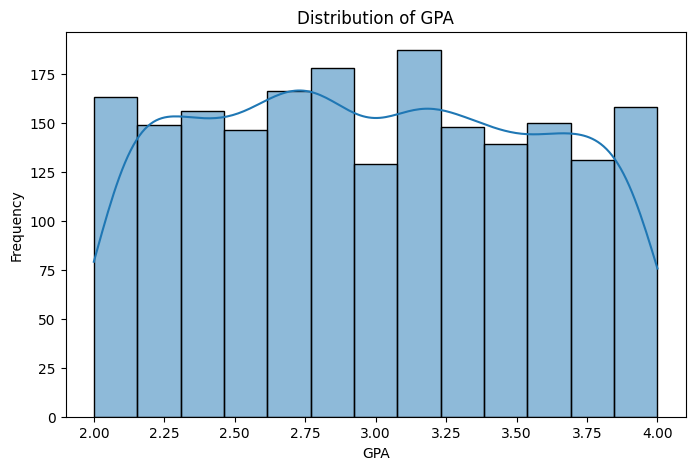

In [138]:
# plotting histogram with KDE
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="GPA", kde=True)
plt.title("Distribution of GPA")
plt.xlabel("GPA")
plt.ylabel("Frequency")
plt.show()

<Axes: ylabel='GPA'>

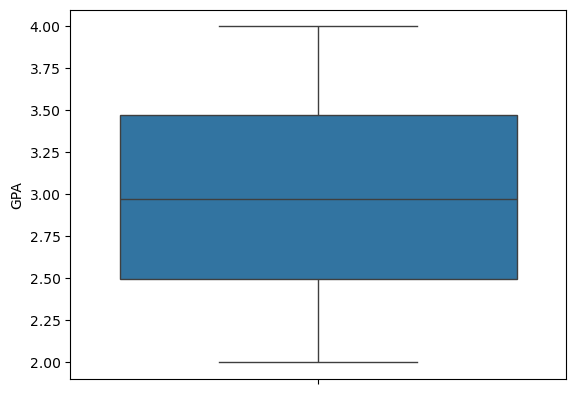

In [26]:
# Boxplot
sns.boxplot(df["GPA"])

## Oberservation

- The GPA values range from low to high academic performance, indicating variation among students.
- Most students have a moderate to high GPA, with values concentrated around the average.
- The distribution appears approximately normal with no strong skewness.
- The boxplot shows no outliers,suggesting that GPA values are generally consistent.
- GPA is expected to be an important feature for predictiong whether a student is academically at risk, as lower GPA values are often associated with higher risk.


# 3. Attendance Rate

In [27]:
# To check statistical information
df["Attendance_Rate"].describe()

count    1991.000000
mean       74.656404
std        14.390081
min        50.000000
25%        62.100000
50%        74.400000
75%        87.100000
max       100.000000
Name: Attendance_Rate, dtype: float64

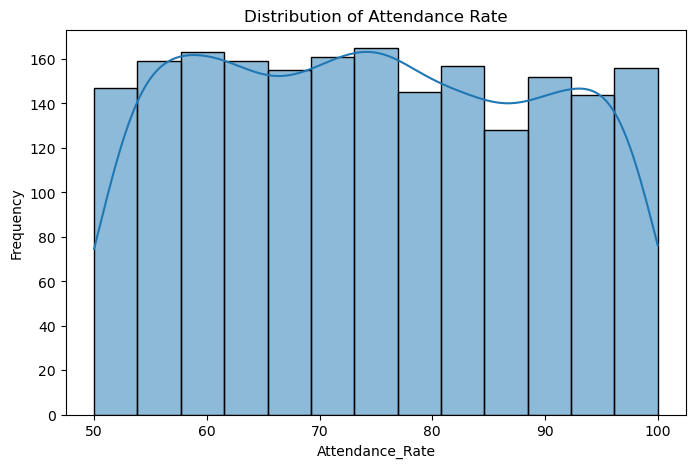

In [28]:
# plotting histogram with KDE
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="Attendance_Rate", kde=True)
plt.title("Distribution of Attendance Rate")
plt.xlabel("Attendance_Rate")
plt.ylabel("Frequency")
plt.show()

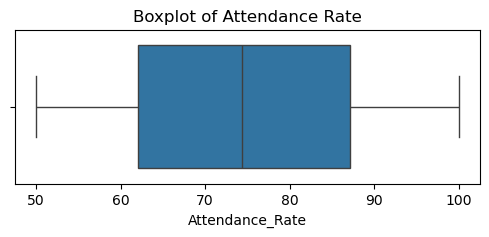

In [29]:
# Boxplot
plt.figure(figsize=(6,2))
sns.boxplot(x=df["Attendance_Rate"])
plt.title("Boxplot of Attendance Rate")
plt.show()

## Observation
- The Attendance Rate values are distributed across a wide range, indicating varying attendance levels among students.
- Most students have a moderate to high attendace rate, as shown by the concentration of values in the histogram.
- The distribution is fairly balanced woth no extreme skewness.
- The boxplot shows no significant outliers, suggesting that attendance values are generally consistent.
- Attendance Rate is likely to be an important predictor of student risk, as lower attendance may be associated with a higher probability of being academically at risk.

# 4. Assignment Submitted

In [30]:
# To check statistical information
df["Assignments_Submitted"].describe()

count    2000.000000
mean        9.612500
std         5.696716
min         0.000000
25%         5.000000
50%        10.000000
75%        15.000000
max        19.000000
Name: Assignments_Submitted, dtype: float64

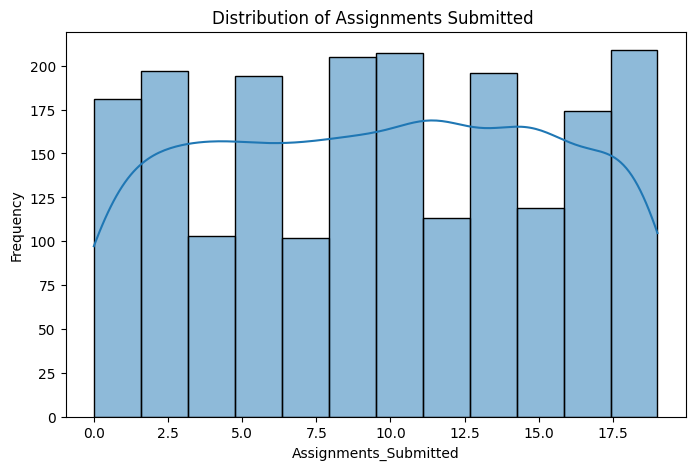

In [144]:
# plotting histogram with KDE
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="Assignments_Submitted", kde=True)
plt.title("Distribution of Assignments Submitted ")
plt.xlabel("Assignments_Submitted")
plt.ylabel("Frequency")
plt.show()

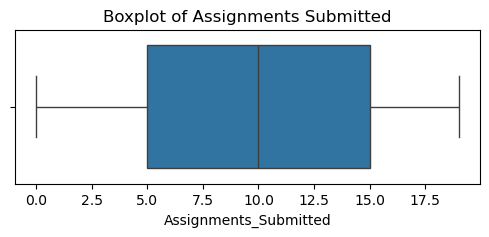

In [31]:
# Boxplot
plt.figure(figsize=(6,2))
sns.boxplot(x=df["Assignments_Submitted"])
plt.title("Boxplot of Assignments Submitted")
plt.show()

## Observation
- The number of assignments submitted varies across students, indicating different levels of academic engagement.
-  Most students submitted a moderate number of assignmnets.
- The distribution is fairly balanced with no extreme concentration on any particular single value.
- The boxplot shows that there are no significant outliers.

# 5. Online Learning Hours

In [32]:
# To check statistical information
df["Online_Learning_Hours"].describe()

count    1996.000000
mean        7.565030
std         4.286298
min         0.000000
25%         3.900000
50%         7.600000
75%        11.300000
max        15.000000
Name: Online_Learning_Hours, dtype: float64

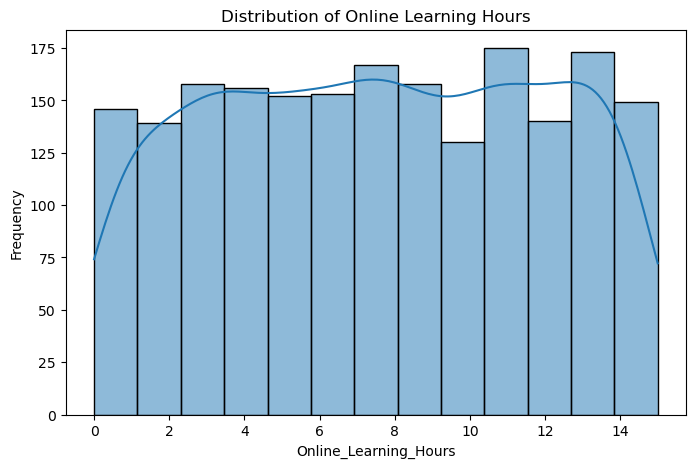

In [33]:
# plotting histogram with KDE
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="Online_Learning_Hours", kde=True)
plt.title("Distribution of Online Learning Hours")
plt.xlabel("Online_Learning_Hours")
plt.ylabel("Frequency")
plt.show()

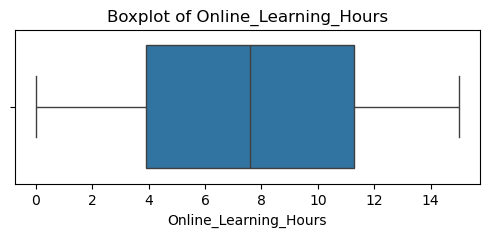

In [34]:
# Boxplot
plt.figure(figsize=(6,2))
sns.boxplot(x=df["Online_Learning_Hours"])
plt.title("Boxplot of Online_Learning_Hours")
plt.show()

## Observation
- Students spend varying amounts of time on online learning activities.
- Most observations are concentrated around the average number of learning hours.
- The distribution is reasonably balanced with no severe skewness.
- Boxplot shows that there are no outliers in online learning hour.

# 5. Forum Participation

In [35]:
# To check statistical information
df["Forum_Participation"].describe()

count    2000.000000
mean        4.400000
std         2.870212
min         0.000000
25%         2.000000
50%         4.000000
75%         7.000000
max         9.000000
Name: Forum_Participation, dtype: float64

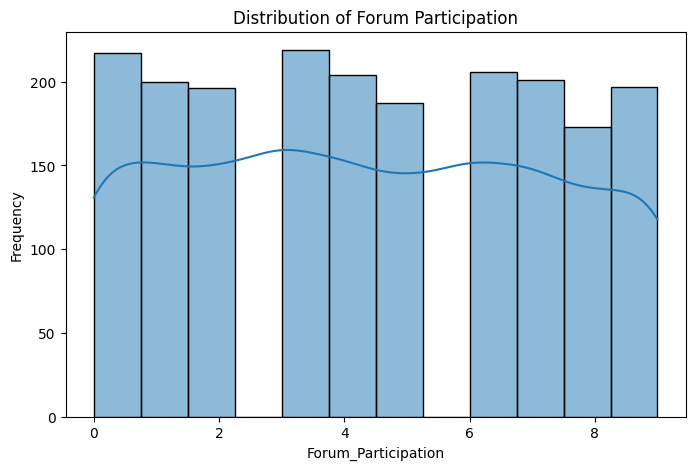

In [150]:
# plotting histogram with KDE
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="Forum_Participation", kde=True)
plt.title("Distribution of Forum Participation")
plt.xlabel("Forum_Participation")
plt.ylabel("Frequency")
plt.show()

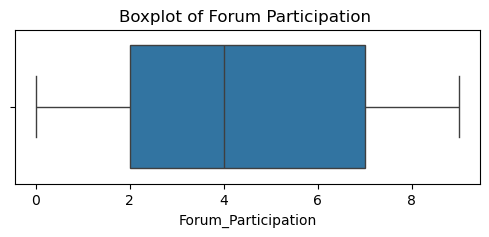

In [36]:
# Boxplot
plt.figure(figsize=(6,2))
sns.boxplot(x=df["Forum_Participation"])
plt.title("Boxplot of Forum Participation ")
plt.show()

## Observation
- Forum Participation differs among students, reflecting different levels of interaction.
- Most students have low to moderate participation.
- The distribution shows variation without extreme values.
- Boxplot shows that there are no significant outliers in this.


#6. Lab Performance

In [37]:
# To check statistical information
df["Lab_Performance"].describe()

count    2000.000000
mean       49.031500
std        28.769139
min         0.000000
25%        24.000000
50%        49.000000
75%        74.000000
max        99.000000
Name: Lab_Performance, dtype: float64

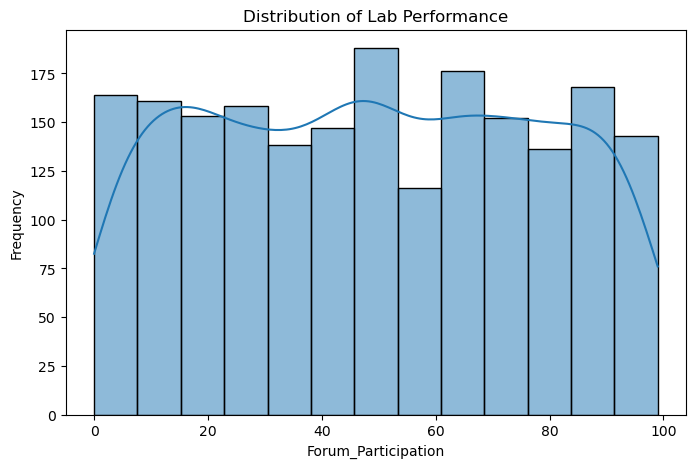

In [38]:
# plotting histogram with KDE
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="Lab_Performance", kde=True)
plt.title("Distribution of Lab Performance")
plt.xlabel("Forum_Participation")
plt.ylabel("Frequency")
plt.show()

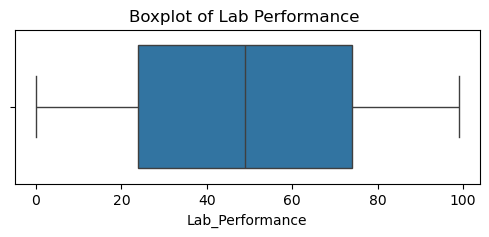

In [39]:
# Boxplot
plt.figure(figsize=(6,2))
sns.boxplot(x=df["Lab_Performance"])
plt.title("Boxplot of Lab Performance ")
plt.show()

## Observation
- Lab performance scores vary across students, indicating differences in pratical performance.
- Most students achieve moderate to high lab performance scores.
- The distribution appears reasonably balanced.
- No major outliers are observed in the boxplot.

# Categorical Features

# Gender


In [40]:
# Count the frequency of each category to see distribution
df["Gender"].value_counts()

Gender
Female    1025
Male       975
Name: count, dtype: int64

In [41]:
# Show percentage distribution of categories
df["Gender"].value_counts(normalize=True)*100

Gender
Female    51.25
Male      48.75
Name: proportion, dtype: float64

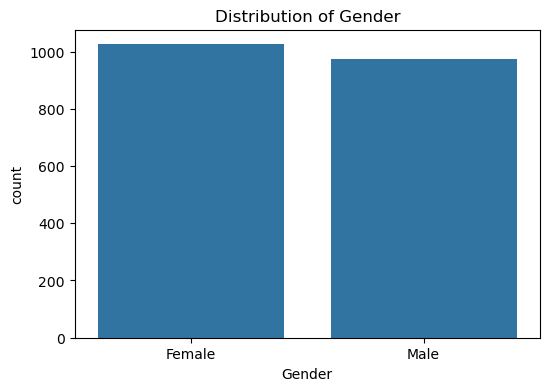

In [42]:
# Plotting count plot
plt.figure(figsize=(6,4))
sns.countplot(x="Gender", data=df)
plt.title("Distribution of Gender")
plt.xlabel("Gender")
plt.ylabel("count")
plt.show()

## Observation
- The dataset contains 1,025 female students and 975 males students.
- The distribution of gender is nearly balanced, with females slightly outnumbering males.
- There is no significant class imbalance in the Gender feature.


# Socio_Economic_Status

In [43]:
# To check null values
df["Socio_Economic_Status"].isnull().sum()

np.int64(19)

In [44]:
# Count the frequency of each category to see distribution
df["Socio_Economic_Status"].value_counts()

Socio_Economic_Status
High      675
Low       672
Medium    634
Name: count, dtype: int64

In [45]:
# Show percentage distribution of categories
df["Socio_Economic_Status"].value_counts(normalize=True)*100

Socio_Economic_Status
High      34.073700
Low       33.922261
Medium    32.004038
Name: proportion, dtype: float64

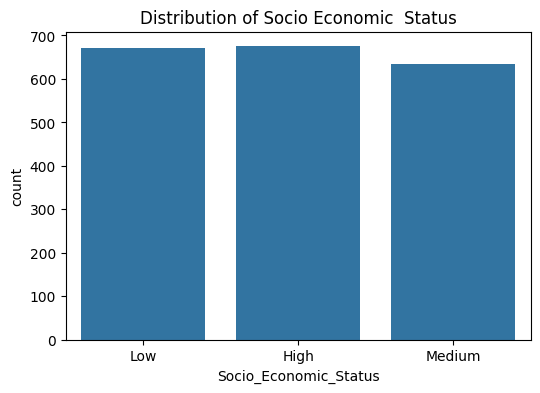

In [161]:
# Plotting count plot
plt.figure(figsize=(6,4))
sns.countplot(x="Socio_Economic_Status", data=df)
plt.title("Distribution of Socio Economic  Status")
plt.xlabel("Socio_Economic_Status")
plt.ylabel("count")
plt.show()

## Observation
- The dataset includes three categories: High, Medium, and Low.
- The three categories are fairly evenly distributed, with High and Low occuring slightly more than medium.
- There are 19 missing values in this feature.

# Extracurricular_Participation

In [46]:
# To check null values
df["Extracurricular_Participation"].isnull().sum()

np.int64(3)

In [47]:
# Count the frequency of each category to see distribution
df["Extracurricular_Participation"].value_counts()

Extracurricular_Participation
1.0    1002
0.0     995
Name: count, dtype: int64

In [48]:
# Show percentage distribution of categories
df["Extracurricular_Participation"].value_counts(normalize=True)*100

Extracurricular_Participation
1.0    50.175263
0.0    49.824737
Name: proportion, dtype: float64

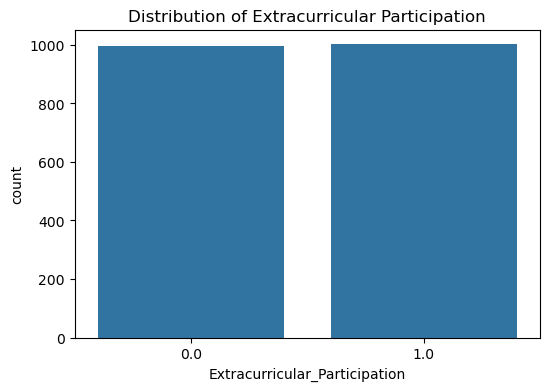

In [49]:
# Plotting count plot
plt.figure(figsize=(6,4))
sns.countplot(x="Extracurricular_Participation", data=df)
plt.title("Distribution of Extracurricular Participation")
plt.xlabel("Extracurricular_Participation")
plt.ylabel("count")
plt.show()

## Observation
- The feature is in binary form, which indicates whether a student participates in extracurricular activities or not.
- The number of students participating and not participating in extracurricular activities are 1002, 995 respectively.
- In this feature only 3 values are present which are missed.

# Target(At Risk)

In [50]:
# Count the frequency of each category to see distribution
df["At_Risk"].value_counts()

At_Risk
0    1423
1     577
Name: count, dtype: int64

In [51]:
# Show percentage distribution of categories
df["At_Risk"].value_counts(normalize=True)*100

At_Risk
0    71.15
1    28.85
Name: proportion, dtype: float64

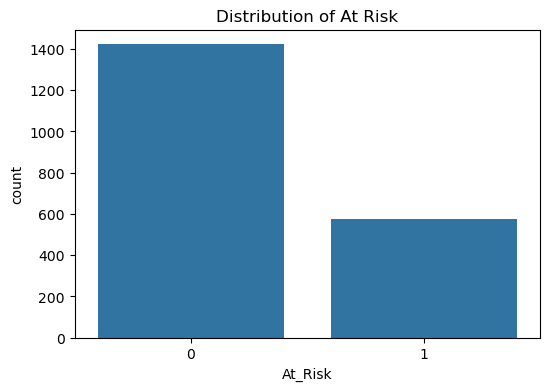

In [53]:
# Plotting count plot
plt.figure(figsize=(6,4))
sns.countplot(x="At_Risk", data=df)
plt.title("Distribution of At Risk")
plt.xlabel("At_Risk")
plt.ylabel("count")
plt.show()

## Observation
- The target variable contains two classes: At Risk(1) and Not Risk(0).
- 1423 students (approx 71%) are Not At Risk, whereas 577 students (approx 29%) are At Risk.
- The target variable is moderately imbalanced,with more students in the Not At Risk class.


# Bivariate Analysis

Bivariate analysis is performed to examine the relationship between two variables. In this project, the primary objective is to understand how each feature is associated with the target variable (At_Risk). This analysis helps identify the factors that influence student academic risk and provides valuable insights for feature selection before building machine learning models.

The analysis includes:

- Relationship between categorical features and the target variable using count plots.
- Relationship between numerical features and the target variable using box plots.
- Analysis of correlations among numerical features using a correlation heatmap to identify the strength and direction of relationships between variables.

# Categorical vs Target

# Gender vs At_Risk

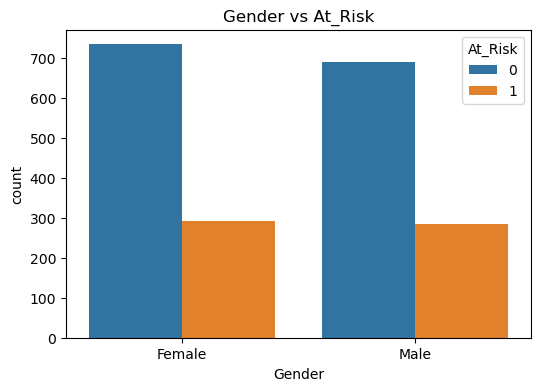

In [54]:
# Plotting count plot
plt.figure(figsize=(6,4))
sns.countplot(x='Gender', hue='At_Risk', data=df)
plt.title("Gender vs At_Risk")
plt.xlabel("Gender")
plt.ylabel("count")
plt.show()

In [56]:
# Create a cross-tabulation to analyze relationship between two categorical variables
pd.crosstab(df["Gender"],df["At_Risk"])

At_Risk,0,1
Gender,,
Female,733,292
Male,690,285


In [57]:
# To Show percentage distribution across two categorical variables
pd.crosstab(df["Gender"],df["At_Risk"], normalize="index")*100

At_Risk,0,1
Gender,,
Female,71.512195,28.487805
Male,70.769231,29.230769


## Observation
- Both male and female students have a approx  similar distribution of At Risk and Not At Risk cases.
- Approximately 71% of both genders are Not At Risk, whereas about 29% are At Risk.
- By observing, we can see that there is no significant difference in academic risk based on gender.

# Socio_Economic_status vs At_Risk

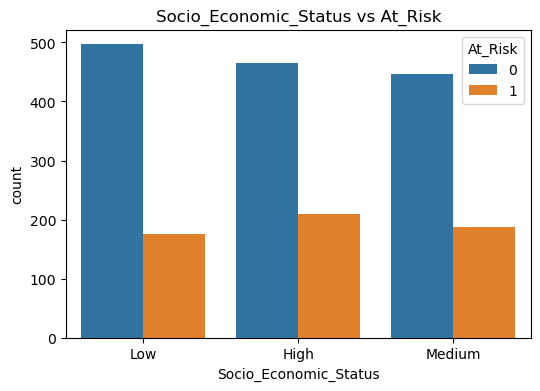

In [58]:
# Plotting count plot
plt.figure(figsize=(6,4))
sns.countplot(x='Socio_Economic_Status', hue='At_Risk', data=df)
plt.title("Socio_Economic_Status vs At_Risk")
plt.xlabel("Socio_Economic_Status")
plt.ylabel("count")
plt.show()

In [59]:
# Create a cross-tabulation to analyze relationship between two categorical variables
pd.crosstab(df["Socio_Economic_Status"],df["At_Risk"])

At_Risk,0,1
Socio_Economic_Status,,
High,465,210
Low,497,175
Medium,447,187


In [60]:
# To Show percentage distribution across two categorical variables
pd.crosstab(df["Socio_Economic_Status"],df["At_Risk"], normalize="index")*100

At_Risk,0,1
Socio_Economic_Status,,
High,68.888889,31.111111
Low,73.958333,26.041667
Medium,70.504732,29.495268


## Observation
- The proportion of At Risk students varies slightly across the three socio-economic groups.
- Students in the high socio-economic category have a slightly higher proportion of At Risk as compared to other groups.
- Students in the low soccio-economic category have the lowest proportion of At Risk cases in this dataset.
- Overall, the difference are not very large, suggesting socio-economic status has only a moderate relationship with the target.

# Extracurricular_Participation vs At_Risk

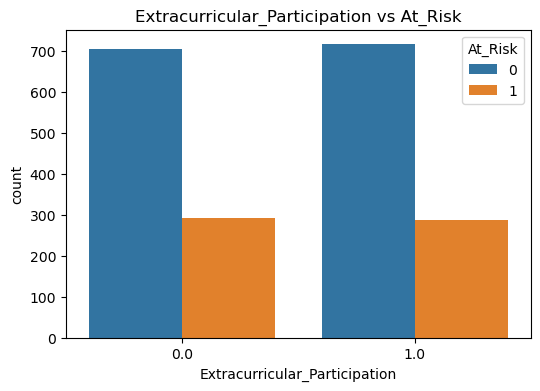

In [62]:
# Plotting count plot
plt.figure(figsize=(6,4))
sns.countplot(x='Extracurricular_Participation', hue='At_Risk', data=df)
plt.title("Extracurricular_Participation vs At_Risk")
plt.xlabel("Extracurricular_Participation")
plt.ylabel("count")
plt.show()

In [63]:
# Create a cross-tabulation to analyze relationship between two categorical variables
pd.crosstab(df["Extracurricular_Participation"],df["At_Risk"])

At_Risk,0,1
Extracurricular_Participation,,
0.0,704,291
1.0,716,286


In [64]:
# To Show percentage distribution across two categorical variables
pd.crosstab(df["Extracurricular_Participation"],df["At_Risk"], normalize="index")*100

At_Risk,0,1
Extracurricular_Participation,,
0.0,70.753769,29.246231
1.0,71.457086,28.542914


## Observation
- Students who participate in extracurricular activities and those who do not have very similar risk distributions.
- Around 71% of students in both groups are not at risk, while 29% are at risk.
- Extracurricular participation alone does not show a strong association with academic risk.

# Numerical vs Target

# Age vs At Risk

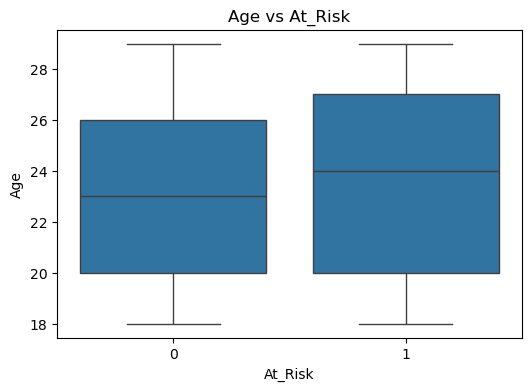

In [65]:
# Box plot
plt.figure(figsize=(6,4))
sns.boxplot(x='At_Risk', y='Age',data=df)
plt.title("Age vs At_Risk")
plt.xlabel("At_Risk")
plt.ylabel("Age")
plt.show()

In [66]:
# Statistical Summary
df.groupby('At_Risk')['Age'].describe()

,count,mean,std,min,25%,50%,75%,max
At_Risk,,,,,,,,
0,1423.0,23.437807,3.466967,18.0,20.0,23.0,26.0,29.0
1,577.0,23.533795,3.583719,18.0,20.0,24.0,27.0,29.0


In [67]:
# Median values
df.groupby('At_Risk')['Age'].median()

At_Risk
0    23.0
1    24.0
Name: Age, dtype: float64

## Observation
-  The median age is 23 years for students who are Not At Risk and 24 years for student who are At Risk.
- The boxplot show a large overlap between both groups.



# GPA vs At_Risk

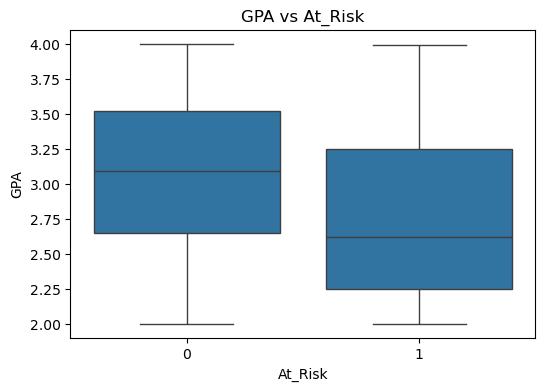

In [68]:
# Box plot
plt.figure(figsize=(6,4))
sns.boxplot(x='At_Risk', y='GPA',data=df)
plt.title("GPA vs At_Risk")
plt.xlabel("At_Risk")
plt.ylabel("GPA")
plt.show()

In [69]:
# Statistical Summary
df.groupby('At_Risk')['GPA'].describe()

,count,mean,std,min,25%,50%,75%,max
At_Risk,,,,,,,,
0,1423.0,3.070878,0.543602,2.0,2.65,3.09,3.52,4.00
1,577.0,2.773830,0.594348,2.0,2.25,2.62,3.25,3.99


In [70]:
# Median values
df.groupby('At_Risk')['GPA'].median()

At_Risk
0    3.09
1    2.62
Name: GPA, dtype: float64

## Observation
- Student who are At Risk have a lower medain GPA(approx 2.62) than students who are Not At Risk(3.09).
- The boxplot shows a clear downward shift in GPA for At Risk Students.


# Attendance_Rate vs At_Risk

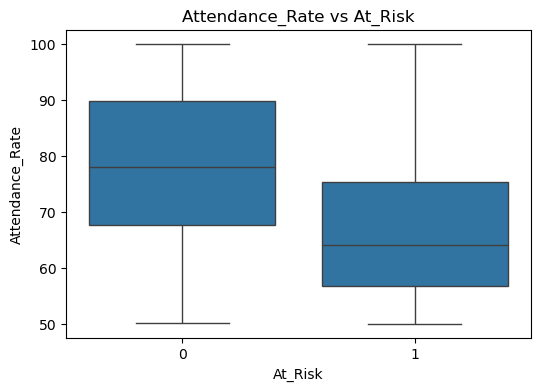

In [71]:
# Box plot
plt.figure(figsize=(6,4))
sns.boxplot(x='At_Risk', y='Attendance_Rate',data=df)
plt.title("Attendance_Rate vs At_Risk")
plt.xlabel("At_Risk")
plt.ylabel("Attendance_Rate")
plt.show()

In [72]:
# Statistical Summary
df.groupby('At_Risk')['Attendance_Rate'].describe()

,count,mean,std,min,25%,50%,75%,max
At_Risk,,,,,,,,
0,1415.0,77.664382,13.754717,50.1,67.6,78.0,89.75,100.0
1,576.0,67.267014,13.207776,50.0,56.8,64.0,75.25,100.0


In [73]:
# Median values
df.groupby('At_Risk')['Attendance_Rate'].median()

At_Risk
0    78.0
1    64.0
Name: Attendance_Rate, dtype: float64

## Observation
- Students who are not at risk have higher attendance rates than those who are at risk.
- The median attendance is lower for the at risk group.
- This indicates that regular attendace is associated with a lower probability of being at risk.

# Assignments_Submitted vs At_Risk

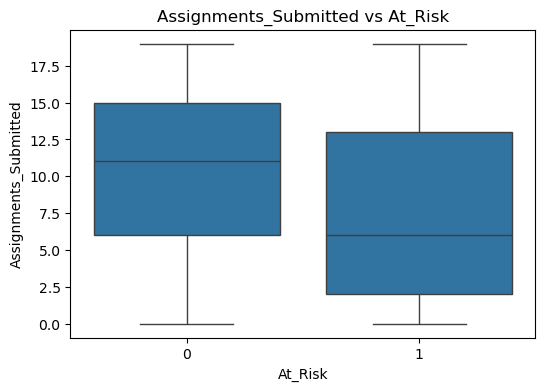

In [74]:
# Box plot
plt.figure(figsize=(6,4))
sns.boxplot(x='At_Risk', y='Assignments_Submitted',data=df)
plt.title("Assignments_Submitted vs At_Risk")
plt.xlabel("At_Risk")
plt.ylabel("Assignments_Submitted")
plt.show()

In [75]:
# Statistical Summary
df.groupby('At_Risk')['Assignments_Submitted'].describe()

,count,mean,std,min,25%,50%,75%,max
At_Risk,,,,,,,,
0,1423.0,10.384399,5.351415,0.0,6.0,11.0,15.0,19.0
1,577.0,7.708839,6.068344,0.0,2.0,6.0,13.0,19.0


In [76]:
# Median values
df.groupby('At_Risk')['Assignments_Submitted'].median()

At_Risk
0    11.0
1     6.0
Name: Assignments_Submitted, dtype: float64

## Observation
- Students who are not at risk submit more assignment on average.
- At Risk students tend to have lower assignment submission count.


# Online_Learning_Hours vs At_Risk

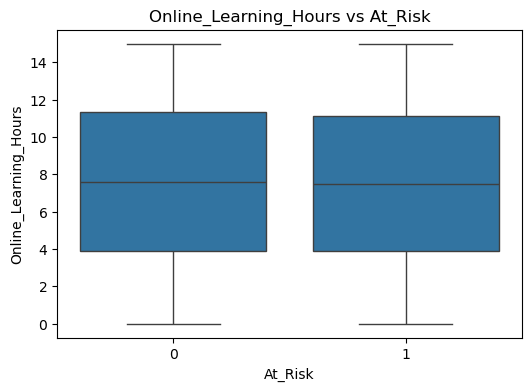

In [77]:
# Box plot
plt.figure(figsize=(6,4))
sns.boxplot(x='At_Risk', y='Online_Learning_Hours',data=df)
plt.title("Online_Learning_Hours vs At_Risk")
plt.xlabel("At_Risk")
plt.ylabel("Online_Learning_Hours")
plt.show()

In [78]:
# Statistical Summary
df.groupby('At_Risk')['Online_Learning_Hours'].describe()

,count,mean,std,min,25%,50%,75%,max
At_Risk,,,,,,,,
0,1419.0,7.616350,4.284776,0.0,3.9,7.6,11.35,15.0
1,577.0,7.438821,4.291143,0.0,3.9,7.5,11.10,15.0


In [79]:
# Median values
df.groupby('At_Risk')['Online_Learning_Hours'].median()

At_Risk
0    7.6
1    7.5
Name: Online_Learning_Hours, dtype: float64

## Observation
- The distribution of online learning hours overlap considerably between two groups.
- Only a small difference can be seen in the median values.

# Forum_Participation vs At_Risk

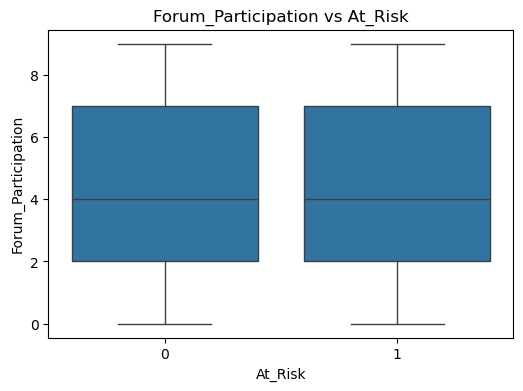

In [80]:
# Box plot
plt.figure(figsize=(6,4))
sns.boxplot(x='At_Risk', y='Forum_Participation',data=df)
plt.title("Forum_Participation vs At_Risk")
plt.xlabel("At_Risk")
plt.ylabel("Forum_Participation")
plt.show()

In [81]:
# Statistical Summary
df.groupby('At_Risk')['Forum_Participation'].describe()

,count,mean,std,min,25%,50%,75%,max
At_Risk,,,,,,,,
0,1423.0,4.436402,2.886020,0.0,2.0,4.0,7.0,9.0
1,577.0,4.310225,2.831332,0.0,2.0,4.0,7.0,9.0


In [82]:
# Median values
df.groupby('At_Risk')['Forum_Participation'].median()

At_Risk
0    4.0
1    4.0
Name: Forum_Participation, dtype: float64

## Observation
- Students who are not at risk generally participate more actively in discussion forums.
- At Risk students show lower forum participation.

# Lab_Performance vs At_Risk

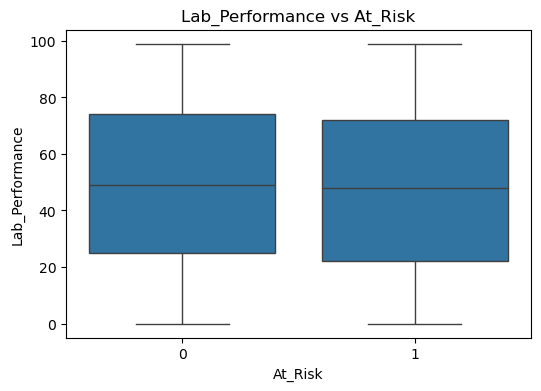

In [83]:
# Box plot
plt.figure(figsize=(6,4))
sns.boxplot(x='At_Risk', y='Lab_Performance',data=df)
plt.title("Lab_Performance vs At_Risk")
plt.xlabel("At_Risk")
plt.ylabel("Lab_Performance")
plt.show()

In [84]:
# Statistical Summary
df.groupby('At_Risk')['Lab_Performance'].describe()

,count,mean,std,min,25%,50%,75%,max
At_Risk,,,,,,,,
0,1423.0,49.551651,28.700426,0.0,25.0,49.0,74.0,99.0
1,577.0,47.748700,28.922867,0.0,22.0,48.0,72.0,99.0


In [85]:
# Median values
df.groupby('At_Risk')['Lab_Performance'].median()

At_Risk
0    49.0
1    48.0
Name: Lab_Performance, dtype: float64

## Observation
- The median lab performance is slightly higher for the students who are not at risk.
- The boxplot overlapping, suggesting only a modest relationship.

# Multivariate Analysis

## Correlation Heatmap

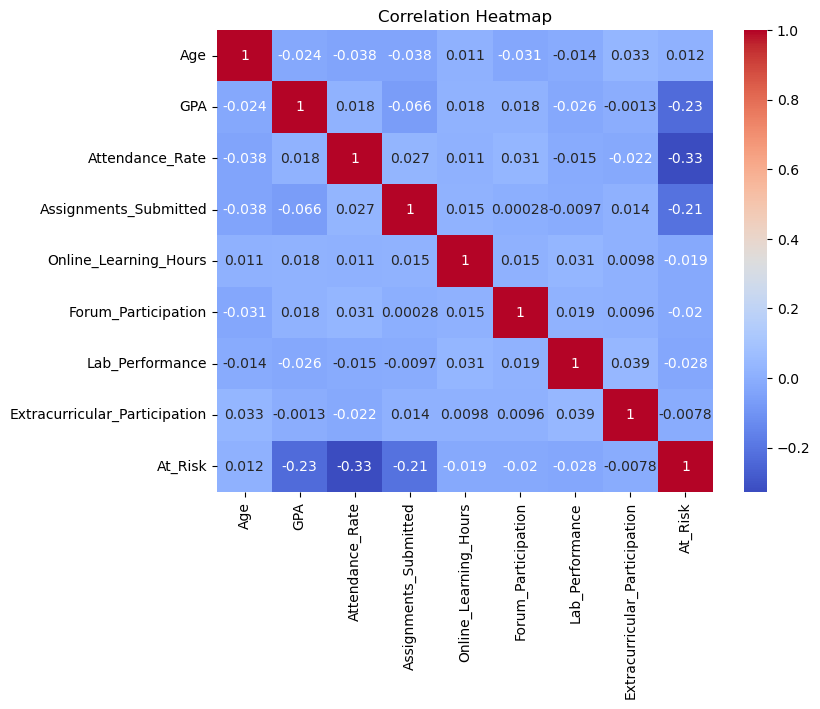

In [86]:
# Plotting Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

## Observation
- Attendance Rate has the strongest negative correlation with At Risk (approx -0.33) indicating that students with higher attendance are less likely to be at academic risk.
- GPA also shows a moderate negative correlation with At Risk (approx -0.23), suggesting that better academic performance is associated with a lower risk level.
- Assignment Submitted has a weak to moderate negative correlation with At Risk (approx -0.21), showing the students who submit more assignments are less likely to be at risk.
- Age, Online Learning Hours, Forum Parrticipation, Lab performance and Extracurricular Participation shows very weak correlation with the target variable, indicating limited linear relationship.
- The numerical features do not exhibit strong correlations with one another, showing that multicollinearity is not a significant concern in this dataset.
- Overall, Attendace Rate, GPA, and Assignment Submitted emerge as the most informative numericall features for predicting student academic risk.

# Data Preprocessing

## Separate Features and Target

In [87]:
# Separating Features and Target
x = df.drop("At_Risk", axis=1)
y = df["At_Risk"]

In [88]:
# Confirming Feature and target shape
print("Feature Shape:", x.shape)
print("Target Shape:" , y.shape)

Feature Shape: (2000, 10)
Target Shape: (2000,)


# Train-Test Split

In [89]:
# Train-Test Split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2,random_state=42,stratify=y)

# Feature Categorization

In [90]:
# Numerical and categorical columns
numerical_features = ['Age','GPA','Attendance_Rate','Assignments_Submitted','Online_Learning_Hours','Forum_Participation','Lab_Performance']
categorical_features = ['Gender','Socio_Economic_Status','Extracurricular_Participation']

# Create Preprocessing Pipelines

In [91]:
# Preprocessing Pipelines
# Numerical Pipeline
numerical_pipeline = Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())])

In [92]:
# Categorical Pipeline
categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),("encoder",OneHotEncoder(handle_unknown="ignore"))])

# Column Transformer

In [93]:
# column Transforming
preprocessor = ColumnTransformer([("numerical", numerical_pipeline, numerical_features), ("categorical", categorical_pipeline, categorical_features)])

# Fit and Transform the Training Data

In [94]:
# Fit and tranform the training data
x_train =  preprocessor.fit_transform(x_train)

# Tranform the Test Data

In [95]:
# Transforming the test data
x_test = preprocessor.transform(x_test)

In [96]:
# Verify the shapes
print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (1600, 14)
Testing data shape: (400, 14)


# Model Building & Evaluation
 In this step, multiple supervised machine learning classificatin models are trained and evaluated to predict whether a student is academically at risk or not. The performance of each model will be compared using various evaluation metrics to identify most suitable model for the prediction task.

## Logistic Regression

In [97]:
# Importing Libraries
from sklearn.linear_model import LogisticRegression

In [98]:
# Creating the model
model = LogisticRegression(random_state=42)

In [99]:
# Train the model
model.fit(x_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [100]:
# Making the Prediction
y_pred = model.predict(x_test)

## Model Evaluation

In [116]:
# Importing Libraries for model evaluation
from sklearn.metrics import accuracy_score,roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [102]:
# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

In [103]:
# Print Accuracy
print("Accuracy:", accuracy)

Accuracy: 0.74


In [104]:
# roc_auc_score
roc_auc_score = roc_auc_score(y_test, y_pred)
print("roc_auc_score",roc_auc_score )

roc_auc_score 0.6334096109839816


In [105]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

In [106]:
# Printing Confusion Matrix
print(cm)

[[252  33]
 [ 71  44]]


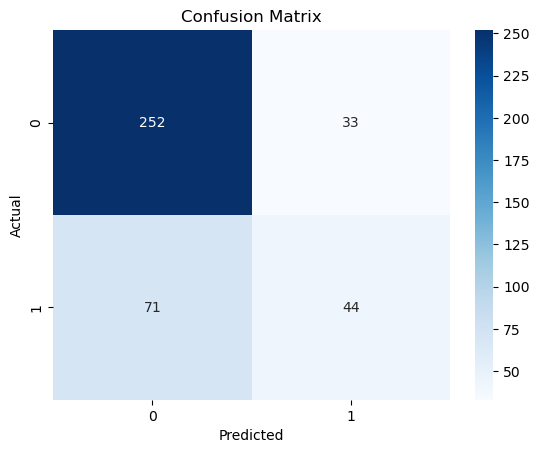

In [107]:
# Plotting Heatmap
sns.heatmap(cm, annot = True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

## Observation
The confusion matrix provides a detailed breakdown of correct and incorrect predictions.

- True Negatives(TN): 252
- False Positives(FP): 33
- False Negatives(FN): 71
- True Positives(TP): 44
This means:
- 252 students were correctly predicted as Not At Risk.
- 33 students were incorrectly predicted as At Risk.
- 71 students were actually At Risk but predicted incorrect as Not At Risk.
- 44 students were correctly predicted as At Risk.


In [108]:
# Print Classification Report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.78      0.88      0.83       285
           1       0.57      0.38      0.46       115

    accuracy                           0.74       400
   macro avg       0.68      0.63      0.64       400
weighted avg       0.72      0.74      0.72       400



## Observation
- The model performs well for the majority class(Not At Risk).
- It performs poorly for the At Risk class, with:
  - Recall = 0.38, meaning it identifies only 38% of the students who are actually At Risk.
  - This is concern because 62% of AT Risk students are missed(71 false negatives).



In [109]:
# predict training and testing data accuracy to check overfitting,underfitting or balanced
train_pred_lr = model.predict(x_train)
test_pred_lr = model.predict(x_test)
print("Training Accuracy:", accuracy_score(y_train, train_pred_lr))
print("Testing Accuracy:", accuracy_score(y_test, test_pred_lr))

Training Accuracy: 0.77
Testing Accuracy: 0.74


## Overall Observation - Logistic Regression
- Logistic Regression model acheived an overall accuracy of 74% on the test dataset.
- The model performed well in indentifying students who are Not At Risk, achieving a high recall of 88%.
- However, the model showed relatively poor performance in predicting At Risk students, with a recall of only 38%.
- The confusion matrix indicates that 71 At Risk students were incorrectly classified as Not At Risk, which is not right for an academic risk prediction.
- The training and testing accuracy have small difference which suggests that model generalizes well to unseen data without significant overfitting.
- Eventhough Logistic Regression provides a reasonable baseline model, its performance for indentifying At Risk students is limited.

# Decision Tree Classifier

In [110]:
# Import the model
from sklearn.tree import DecisionTreeClassifier

In [111]:
# Create the model
dt = DecisionTreeClassifier(random_state=42)

In [112]:
# Train the model
dt.fit(x_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [113]:
# Make Predictions
y_pred_dt = dt.predict(x_test)

## Evaluate the model

In [114]:
# Accuracy
accuracy_dt = accuracy_score(y_test, y_pred_dt)
print("Accuracy", accuracy_dt)

Accuracy 0.7325


In [117]:
# roc_auc_score
RocAucScore = roc_auc_score(y_test, y_pred_dt)
print("roc_auc_score",RocAucScore )

roc_auc_score 0.6748283752860411


In [118]:
# Confusion Matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)
print(cm_dt)


[[231  54]
 [ 53  62]]


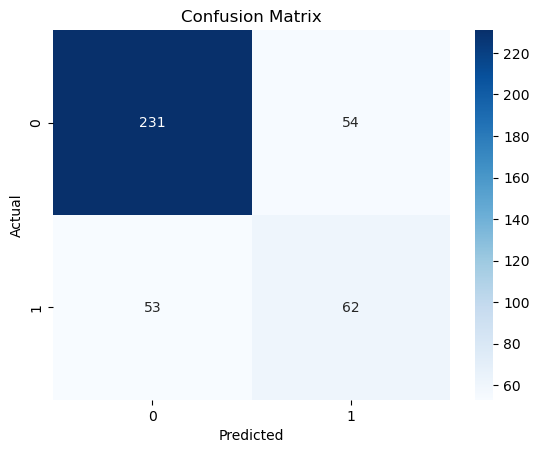

In [119]:
# Plotting Heatmap
sns.heatmap(cm_dt, annot = True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [120]:
# Print Classification Report
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.81      0.81      0.81       285
           1       0.53      0.54      0.54       115

    accuracy                           0.73       400
   macro avg       0.67      0.67      0.67       400
weighted avg       0.73      0.73      0.73       400



In [121]:
# predict training and testing data accuracy to check overfitting,underfitting or balanced
train_pred_dt = dt.predict(x_train)
test_pred_dt = dt.predict(x_test)
print("Training Accuracy:", accuracy_score(y_train, train_pred_dt))
print("Testing Accuracy:", accuracy_score(y_test, test_pred_dt))

Training Accuracy: 1.0
Testing Accuracy: 0.7325


## Overall Observation - Decision Tree Classifier
- The decision tree classifier acheived an accuracy of 73% and a ROC-AUC score of 0.67.
- The model correctly identified 231 Not At Risk and 62 At Risk students.
- It achieved a precision of 53%,recall of 54%, and F1-score Of 54% for the At Risk class.
- The training and testing shows a large performance gap. This confirms that the model is overfitting.
- when we comapre decision Tree with Logistic Regression, the decision tree predicted more At Risk students, resulting in higher recall and F1-score.
- Although the accuracy is slightly lower, the model performs well for identifying students who are academically at Risk.

# Random Forest Classifier

In [122]:
# Import thr model
from sklearn.ensemble import RandomForestClassifier

In [123]:
# Create the model
rf = RandomForestClassifier(random_state=42)

In [124]:
# Train the model
rf.fit(x_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [125]:
# Make predictions
y_pred_rf = rf.predict(x_test)

In [126]:
# Evaluate the model
# Accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("Accuracy", accuracy_rf)

Accuracy 0.77


In [127]:
# roc_auc_score
RocAucScore = roc_auc_score(y_test, y_pred_rf)
print("roc_auc_score",RocAucScore )

roc_auc_score 0.6674294431731501


In [128]:
# Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
print(cm_rf)

[[259  26]
 [ 66  49]]


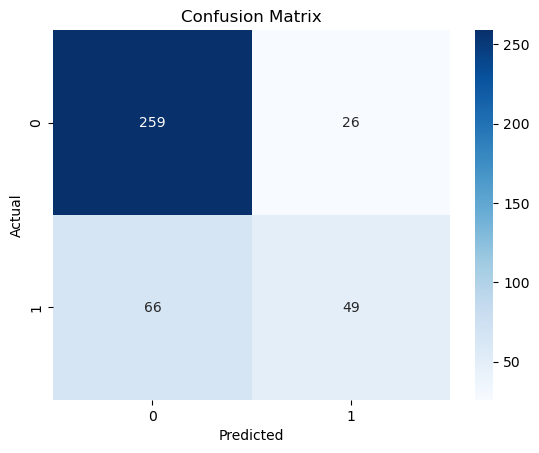

In [129]:
# Plotting Heatmap
sns.heatmap(cm_rf, annot = True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [130]:
# Print Classification Report
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.80      0.91      0.85       285
           1       0.65      0.43      0.52       115

    accuracy                           0.77       400
   macro avg       0.73      0.67      0.68       400
weighted avg       0.76      0.77      0.75       400



In [131]:
# predict training and testing data accuracy to check overfitting,underfitting or balanced
train_pred_rf = rf.predict(x_train)
test_pred_rf = rf.predict(x_test)
print("Training Accuracy:", accuracy_score(y_train, train_pred_rf))
print("Testing Accuracy:", accuracy_score(y_test, test_pred_rf))

Training Accuracy: 1.0
Testing Accuracy: 0.77


## Overall Observation - Random Forest Classifier
- This models acheived an accuracy of 77% and a ROC-AUC score of 0.667..
- Precision, recall, F1-score for this models is acheived as 65%, 43%, 52% respectively for the At Risk students.
- The training accuracy is 100%, while the  testing accuracy is 77% describing overfitting .
- As comparison to other evaluated models, this model performs well having better accuracy and precision but it has less recall.

# K-Nearest Neighbours(KNN)

In [132]:
# Import thr model
from sklearn.neighbors import KNeighborsClassifier

In [133]:
# Create the model
knn = KNeighborsClassifier(n_neighbors=5)

In [134]:
# Train the model
knn.fit(x_train,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [135]:
# Make predictions
y_pred_knn = knn.predict(x_test)

In [136]:
# Evaluate the model
print("Accuracy:", accuracy_score(y_test,y_pred_knn))
print("\nROC-AUC:", roc_auc_score(y_test, y_pred_knn))
print("\nConfusion Matrix:\n", confusion_matrix(y_test,y_pred_knn))
print("\nClassification report:\n", classification_report(y_test,y_pred_knn))

Accuracy: 0.7275

ROC-AUC: 0.6194508009153319

Confusion Matrix:
 [[249  36]
 [ 73  42]]

Classification report:
               precision    recall  f1-score   support

           0       0.77      0.87      0.82       285
           1       0.54      0.37      0.44       115

    accuracy                           0.73       400
   macro avg       0.66      0.62      0.63       400
weighted avg       0.71      0.73      0.71       400



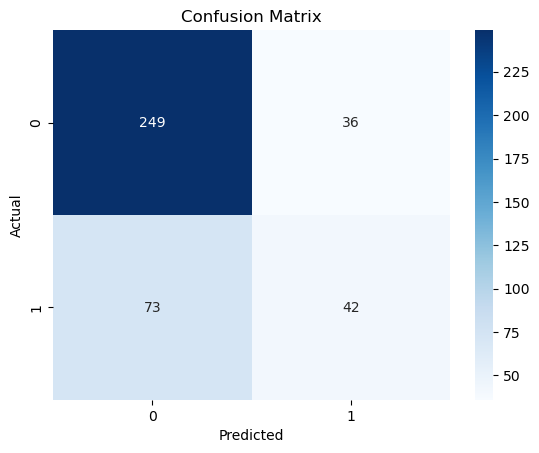

In [137]:
# Plotting Heatmap
sns.heatmap(confusion_matrix(y_test,y_pred_knn), annot = True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [138]:
# predict training and testing data accuracy to check overfitting,underfitting or balanced
train_pred_knn = knn.predict(x_train)
test_pred_knn = knn.predict(x_test)
print("Training Accuracy:", accuracy_score(y_train, train_pred_knn))
print("Testing Accuracy:", accuracy_score(y_test, test_pred_knn))

Training Accuracy: 0.825
Testing Accuracy: 0.7275


## Overall Observation - K-Nearest Neighbours(KNN)
- This models acheived an accuracy of 72.75% and a ROC-AUC score of 0.6194.
- Precision, recall, F1-score for this models is acheived as 54%, 37%, 44%  respectively for the At Risk students.
- From the training(82.5%) and testing(72.75%) accuracy ,we can see there is a slight overfitting .
- This model have overall less performance as comparsion to other evaluated models.

# Support Vector Machine(SVM)

In [139]:
# Import thr model
from sklearn.svm import SVC

In [140]:
# Create the model
svm = SVC(random_state=42)

In [141]:
# Train the model
svm.fit(x_train,y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [142]:
# Make predictions
y_pred_svm = svm.predict(x_test)

In [143]:
# Evaluate the model
print("Accuracy:", accuracy_score(y_test,y_pred_svm))
print("\nROC-AUC:", roc_auc_score(y_test, y_pred_svm))
print("\nConfusion Matrix:\n", confusion_matrix(y_test,y_pred_svm))
print("\nClassification report:\n", classification_report(y_test,y_pred_svm))

Accuracy: 0.7575

ROC-AUC: 0.6534706331045004

Confusion Matrix:
 [[256  29]
 [ 68  47]]

Classification report:
               precision    recall  f1-score   support

           0       0.79      0.90      0.84       285
           1       0.62      0.41      0.49       115

    accuracy                           0.76       400
   macro avg       0.70      0.65      0.67       400
weighted avg       0.74      0.76      0.74       400



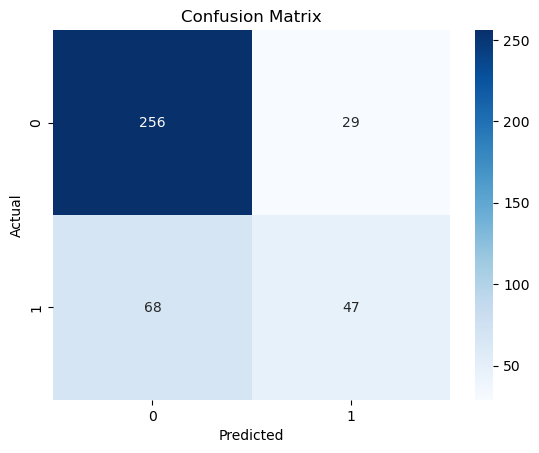

In [144]:
# Plotting Heatmap
sns.heatmap(confusion_matrix(y_test,y_pred_svm), annot = True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [145]:
# predict training and testing data accuracy to check overfitting,underfitting or balanced
train_pred_svm = svm.predict(x_train)
test_pred_svm = svm.predict(x_test)
print("Training Accuracy:", accuracy_score(y_train, train_pred_svm))
print("Testing Accuracy:", accuracy_score(y_test, test_pred_svm))

Training Accuracy: 0.818125
Testing Accuracy: 0.7575


## Overall Analysis - Support Vector Machine
- This model acheived an accuracy of 75.75% and a ROC-AUC score of 0.6534.
- Also this model acheived precision of 62%, recall of 41%, and F1-score of 49% for the At Risk class.
- The training and testing accuracy depicts that there is a small difference between both of them.
- This suggests that the model generalizes well and does not exhibit overfitting.
- This model performed better than Logistic Regression and KNN.

# Gradient Boosting Classifier

In [146]:
# Import thr model
from sklearn.ensemble import GradientBoostingClassifier

In [147]:
# Create the model
gb = GradientBoostingClassifier(random_state=42)

In [148]:
# Train the model
gb.fit(x_train,y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [151]:
# Make predictions
y_pred_gb = gb.predict(x_test)

In [152]:
# Evaluate the model
print("Accuracy:", accuracy_score(y_test,y_pred_gb))
print("\nROC-AUC:", roc_auc_score(y_test, y_pred_gb))
print("\nConfusion Matrix:\n", confusion_matrix(y_test,y_pred_gb))
print("\nClassification report:\n", classification_report(y_test,y_pred_gb))

Accuracy: 0.79

ROC-AUC: 0.707398932112891

Confusion Matrix:
 [[257  28]
 [ 56  59]]

Classification report:
               precision    recall  f1-score   support

           0       0.82      0.90      0.86       285
           1       0.68      0.51      0.58       115

    accuracy                           0.79       400
   macro avg       0.75      0.71      0.72       400
weighted avg       0.78      0.79      0.78       400



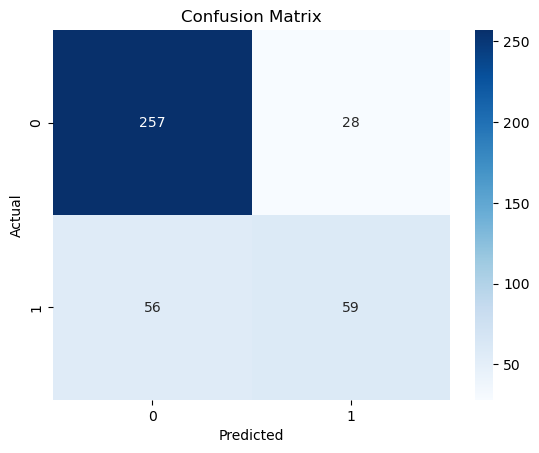

In [153]:
# Plotting Heatmap
sns.heatmap(confusion_matrix(y_test,y_pred_gb), annot = True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [154]:
# predict training and testing data accuracy to check overfitting,underfitting or balanced
train_pred_gb = gb.predict(x_train)
test_pred_gb = gb.predict(x_test)
print("Training Accuracy:", accuracy_score(y_train, train_pred_gb))
print("Testing Accuracy:", accuracy_score(y_test, test_pred_gb))

Training Accuracy: 0.861875
Testing Accuracy: 0.79


## Overall Analysis - Gradient Boosting Classifier
- This model achieved the highest overall performance among all the evaluated models, with accuracy of 79% and ROC-AUC score of 0.707.
- The model achieved precision of 68%, recall of 51% and F1-score of 58% for the At Risk class.
- The training and testing , 86.19% and 79% indicates only a moderate difference between training and testing performance.This suggest that model generalize with only slight overfitting.
- overall, the model provides best balance between accuracy, ROC-AUC, precision, recall, F1-score and generalization making model more suitable for student performance risk prediction system.   

# Comparison Model

In [155]:
# Creating Comparison Model
comparison_df = pd.DataFrame({
    "Model": ["Logistic Regression","Decision Tree","Random Forest","KNN","SVM","Gradient Boosting"],

    "Accuracy": [0.74,0.7325,0.77,0.7275,0.7575,0.79],

    "Precision": [0.57,0.53,0.65,0.54,0.62,0.68],

    "Recall": [0.38,0.54, 0.43,0.37,0.41,0.51],

    "F1-Score": [0.46, 0.54,0.52,0.44,0.49,0.58],

    "ROC-AUC": [0.633,0.670, 0.667,0.619,0.653,0.707],

    "Train Accuracy": [0.77, 1.00, 1.00, 0.8225, 0.8181, 0.8619],

    "Test Accuracy":[0.74,0.73,0.77,0.72,0.75,0.79]
})
comparison_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Train Accuracy,Test Accuracy
0,Logistic Regression,0.7400,0.57,0.38,0.46,0.633,0.7700,0.74
1,Decision Tree,0.7325,0.53,0.54,0.54,0.670,1.0000,0.73
2,Random Forest,0.7700,0.65,0.43,0.52,0.667,1.0000,0.77
3,KNN,0.7275,0.54,0.37,0.44,0.619,0.8225,0.72
4,SVM,0.7575,0.62,0.41,0.49,0.653,0.8181,0.75
5,Gradient Boosting,0.7900,0.68,0.51,0.58,0.707,0.8619,0.79


In [156]:
# Sorting on the basis of accuracy
comparison_df.sort_values(by="Accuracy", ascending=False)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Train Accuracy,Test Accuracy
5,Gradient Boosting,0.7900,0.68,0.51,0.58,0.707,0.8619,0.79
2,Random Forest,0.7700,0.65,0.43,0.52,0.667,1.0000,0.77
4,SVM,0.7575,0.62,0.41,0.49,0.653,0.8181,0.75
0,Logistic Regression,0.7400,0.57,0.38,0.46,0.633,0.7700,0.74
1,Decision Tree,0.7325,0.53,0.54,0.54,0.670,1.0000,0.73
3,KNN,0.7275,0.54,0.37,0.44,0.619,0.8225,0.72


# Model Selection
- Based on the comparison of all six supervised machine learning models, the Gradient Boosting Classifier is selected as the final model. It achieved the highest accuracy(79%),highest precision(68%),highest F1-Score(58%),and the highest ROC-AUC score(0.707) among all evaluated models.
- Also the model shows good generalization, with a training accuracy of 86.19% and a testing of 79% indicating only slightly overfitting.
- Although the Decision tree classifier have slightly high recall to indentify At Risk students but it suffered from significant overfitting.Similarly, Random Forest also show good performance but exhibited overfitting.
- Therefore, the Gradient Boosting Classifier is selected as the final model as it provides overall best performance to predict the students at risk.

# Hyperparameter Tuning
Hyperparameter tuning is performed to identify the optimal combination of model parameters that improves predictive performance and generalization.In this project, we will use RandomizedSearchCV is used to efficiently optimized the selected Gradient Bossting classifier.

In [157]:
# Import RandomizedSearchCV
from sklearn.model_selection import RandomizedSearchCV

In [158]:
# Define the Hyperparameter Search Space
param_dist = {
    "n_estimators": [50, 100, 150, 200],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [2, 3, 4, 5],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

In [159]:
# Create the RandomizedSearchCV object
random_search = RandomizedSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=20,
    scoring="accuracy",
    cv=5,
    random_state=42,
    n_jobs=-1
)

## Hyperparameter Optimization
RandomizedSearchCV was applied to the selected Gradient Boosting classifier to identify the optimal combination of hyperparameters.The search was performed using 5-fold cross-validation over multiple randomly selected parameter combinations. The best-performing hyperparameters were selected based on cross-validation accuracy and used to build the fiinal optimized model.

In [162]:
# Train the RandomizedSearchCV
random_search.fit(x_train,y_train)

,estimator,GradientBoost...ndom_state=42)
,param_distributions,"{'learning_rate': [0.01, 0.05, ...], 'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,n_iter,20
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [163]:
# Display the Best Hyperparameters
print("Best Parameters:", random_search.best_params_)

Best Parameters: {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 2, 'learning_rate': 0.05}


In [164]:
# Display the Best Cross-Validation Score
print("Best Cross Validation Accuracy:", random_search.best_score_)

Best Cross Validation Accuracy: 0.796875


## Train and evaluate the optimized model

In [165]:
# Get the Best Model
best_gb = random_search.best_estimator_

In [166]:
# Making predictions
y_pred_best = best_gb.predict(x_test)

In [167]:
# Evaluating optimized model
print("Accuracy:", accuracy_score(y_test,y_pred_best))
print("\nROC-AUC:", roc_auc_score(y_test, best_gb.predict_proba(x_test)[:, 1]))
print("\nConfusion Matrix:\n", confusion_matrix(y_test,y_pred_best))
print("\nClassification report:\n", classification_report(y_test,y_pred_best))

Accuracy: 0.8075

ROC-AUC: 0.8215713196033562

Confusion Matrix:
 [[261  24]
 [ 53  62]]

Classification report:
               precision    recall  f1-score   support

           0       0.83      0.92      0.87       285
           1       0.72      0.54      0.62       115

    accuracy                           0.81       400
   macro avg       0.78      0.73      0.74       400
weighted avg       0.80      0.81      0.80       400



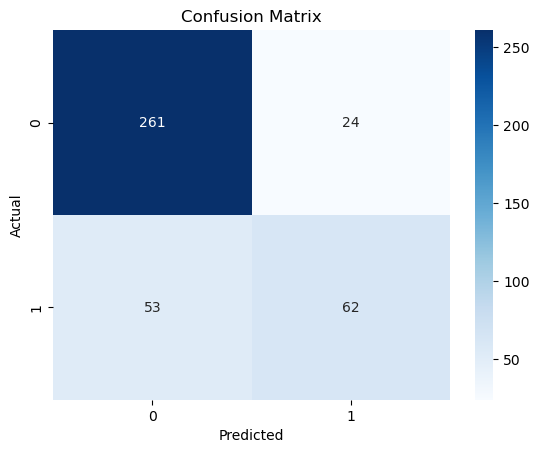

In [168]:
# Plotting Heatmap
sns.heatmap(confusion_matrix(y_test,y_pred_best), annot = True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [169]:
# predict training and testing data accuracy to check overfitting,underfitting or balanced
train_acc = best_gb.score(x_train,y_train)
test_acc = best_gb.score(x_test,y_test)
print("Training Accuracy:", train_acc)
print("Testing Accuracy:", test_acc)

Training Accuracy: 0.805
Testing Accuracy: 0.8075


## Overall Observation
- After hyperparameter tunning using RandomizedSearchCV, the optimized Gradient Boosting model acheived an accuracy of 80.75% and ROC-AUC score of 0.8215, showing a clear improvement over the default model. The model correctly classified 261 not at risk and 62 at risk students.
- It acheived a precision of 72%, recall of 54%, and F1-score of 63% for the at-risk class, indicating better idnetification of student at risk.
- The training accuracy(80.5%) and testing accuracy(80.75%) are very close, suggesting that the model generalizes well and does not exhibit overfitting.
- Therefore, the optimized Gradient Boosting model was selected as the final model for deployment in the Student Performance Risk Prediction System.

# Comparison between Default vs Optimized Model

In [170]:
# Creating Comparison Table
comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "ROU-AUC", "Precision(Class 1)", "Recall(Class 1)", "F1-Score(Class 1)", "Training Accuracy", "Testing Accuracy"],

    "Default Gradient Boosting": [0.79, 0.7074, 0.68, 0.51, 0.58, 0.8619, 0.79],

    "Optimized Gradient Boosting":[0.8075, 0.8215, 0.72, 0.54, 0.63, 0.8050, 0.8075]
})
comparison_df

,Metric,Default Gradient Boosting,Optimized Gradient Boosting
0,Accuracy,0.7900,0.8075
1,ROU-AUC,0.7074,0.8215
2,Precision(Class 1),0.6800,0.7200
3,Recall(Class 1),0.5100,0.5400
4,F1-Score(Class 1),0.5800,0.6300
5,Training Accuracy,0.8619,0.8050
6,Testing Accuracy,0.7900,0.8075


## Comparison Observation
From the above comparison table, it can directly be seen that optimized Gradient Boosting Model outperformed the default model across most evaluation metircs.
- Hyperparameter tuning increased not only the accuracy from 79.00% to 80.75% but also increase ROC-AUC score from 0.7074 to 0.8215.
- The precision, recall, and F1-score for the at-risk class also improved, resulting in better identification of student risk.
- Thus, the optimized model show excellent  generalization, with training and testing accuracies being nearly identical.
- overall,  these results confirm that hyperparameter tunning enhanced the model predictive performance and robustness.

# Model Saving

In [171]:
# Import joblib
import joblib

In [172]:
# saving the preprocessing pipeline
joblib.dump(preprocessor, "preprocessor.pkl")

['preprocessor.pkl']

In [173]:
# Save the optimal model
joblib.dump(best_gb,"student_risk_model.pkl")

['student_risk_model.pkl']

In [174]:
# Verifying that the files are saved
import os
print(os.listdir())

['.ipynb_checkpoints', 'preprocessor.pkl', 'risk_students (3).csv', 'Student_Performance_Risk_Prediction (5).ipynb', 'student_risk_model.pkl']


In [178]:
# Load the saved files(verfication)
loaded_preprocessor = joblib.load("preprocessor.pkl")
loaded_model = joblib.load("student_risk_model.pkl")

print("Model and Preprocessor loaded successfully!")


Model and Preprocessor loaded successfully!


In [179]:
# Verify the loaded objects
print(type(loaded_preprocessor))
print(type(loaded_model))

<class 'sklearn.compose._column_transformer.ColumnTransformer'>
<class 'sklearn.ensemble._gb.GradientBoostingClassifier'>


# Observation
The optimized Gradient Boosting model and the preprocessing pipeline were successfully saved and reloaded using joblib. Saving these objects enables the trained model to be reused for future predictions without retraining and ensures consistent preprocessing of new input data during deployment.